## Linear Regression

Suppose we are given a dataset of $n$ independent observations

$$
\mathcal{D} = \left\{ \left(\mathbf{x}^{(i)}, y^{(i)}\right) \right\}_{i=1}^{n},
$$

where each input $\mathbf{x}^{(i)} \in \mathbb{R}^{d}$ is a $d$-dimensional feature vector and each target $y^{(i)} \in \mathbb{R}$ is a scalar. We assume that the inputs and targets are related through an unknown function $f$, perturbed by additive noise:

$$
y = f(\mathbf{x}) + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, \sigma^{2}),
$$

where the noise term $\varepsilon$ is assumed to be Gaussian with zero mean and variance $\sigma^{2}$, and independent of $\mathbf{x}$.

A linear regression model approximates $f$ under the assumption that the underlying relationship between $\mathbf{x}$ and $y$ is linear. The model's prediction for the $i$-th observation is given by

$$
\hat{y}^{(i)} = \hat{f}\left(\mathbf{x}^{(i)}\right) = \mathbf{w}^{\top} \mathbf{x}^{(i)} + b,
$$

where $\mathbf{w} = (w_1, w_2, \ldots, w_d)^{\top} \in \mathbb{R}^{d}$ is the weight vector and $b \in \mathbb{R}$ is the bias (intercept) term. Expanding the inner product, this can be written equivalently as

$$
\hat{y}^{(i)} = w_1 x_1^{(i)} + w_2 x_2^{(i)} + \cdots + w_d x_d^{(i)} + b = \sum_{j=1}^{d} w_j x_j^{(i)} + b.
$$

> **Remark.** The bias term can be absorbed into the weight vector by augmenting each input with a constant feature, i.e. $\tilde{\mathbf{x}}^{(i)} = \left(1, x_1^{(i)}, \ldots, x_d^{(i)}\right)^{\top}$ and $\tilde{\mathbf{w}} = (b, w_1, \ldots, w_d)^{\top}$, so that $\hat{y}^{(i)} = \tilde{\mathbf{w}}^{\top} \tilde{\mathbf{x}}^{(i)}$.

### Training

The parameters $\mathbf{w}$ and $b$ are estimated from the data by minimizing a loss function that measures the discrepancy between the model's predictions and the observed targets. The standard choice is the mean squared error (MSE):

$$
\mathcal{L}(\mathbf{w}, b) = \frac{1}{n} \sum_{i=1}^{n} \left( y^{(i)} - \hat{y}^{(i)} \right)^{2} = \frac{1}{n} \sum_{i=1}^{n} \left( y^{(i)} - \mathbf{w}^{\top} \mathbf{x}^{(i)} - b \right)^{2}.
$$

This choice follows directly from the Gaussian noise assumption: since $y^{(i)} \mid \mathbf{x}^{(i)} \sim \mathcal{N}\left(\mathbf{w}^{\top} \mathbf{x}^{(i)} + b, \sigma^{2}\right)$, maximizing the likelihood of the observed data is equivalent to minimizing the sum of squared residuals. In other words, the least-squares estimator coincides with the maximum likelihood estimator.

Using the augmented notation from the remark above, let $\mathbf{X} \in \mathbb{R}^{n \times (d+1)}$ be the design matrix whose $i$-th row is $\left(\tilde{\mathbf{x}}^{(i)}\right)^{\top}$, and let $\mathbf{y} = \left(y^{(1)}, \ldots, y^{(n)}\right)^{\top} \in \mathbb{R}^{n}$. The loss can then be written compactly as

$$
\mathcal{L}(\tilde{\mathbf{w}}) = \frac{1}{n} \left\lVert \mathbf{y} - \mathbf{X} \tilde{\mathbf{w}} \right\rVert_2^{2}.
$$

Because this function is convex in $\tilde{\mathbf{w}}$, any stationary point is a global minimum. Setting the gradient to zero yields the **normal equations** $\mathbf{X}^{\top} \mathbf{X} \tilde{\mathbf{w}} = \mathbf{X}^{\top} \mathbf{y}$. Provided that $\mathbf{X}^{\top} \mathbf{X}$ is invertible, they have the closed-form solution

$$
\hat{\mathbf{w}} = \left( \mathbf{X}^{\top} \mathbf{X} \right)^{-1} \mathbf{X}^{\top} \mathbf{y}.
$$

Computing this solution requires solving a $(d+1) \times (d+1)$ linear system, which costs $\mathcal{O}(d^{3})$. This becomes impractical when the number of features is large. In such cases, the parameters are instead found iteratively by **gradient descent**. Starting from an initial guess, the weights are repeatedly updated in the direction of steepest descent:

$$
\tilde{\mathbf{w}}_{t+1} = \tilde{\mathbf{w}}_{t} - \eta \, \nabla \mathcal{L}(\tilde{\mathbf{w}}_{t}) = \tilde{\mathbf{w}}_{t} + \frac{2\eta}{n} \mathbf{X}^{\top} \left( \mathbf{y} - \mathbf{X} \tilde{\mathbf{w}}_{t} \right),
$$

where $\eta > 0$ is the learning rate. For very large datasets, stochastic or mini-batch variants of gradient descent are commonly used. These estimate the gradient from a random subset of the observations at each step.

In [144]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

class LinearRegression:

    def __init__(self, num_features, learning_rate=0.01, n_epochs=100):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.w = np.random.randn(num_features)
        self.b = 0.0
        self.num_features = num_features

    def fit(self, X, y):

 
        for _ in range(self.n_epochs):
            for i in range(X.shape[0]):
                error = y[i] - (X[i] @ self.w + self.b)
                # Gradient of (y_i - w^T x_i - b)^2 is -2 * error * x_i
                self.w += 2 * self.learning_rate * error * X[i]
                self.b += 2 * self.learning_rate * error
 
 
        return self
    
    def predict(self, X):
        return X @ self.w + self.b


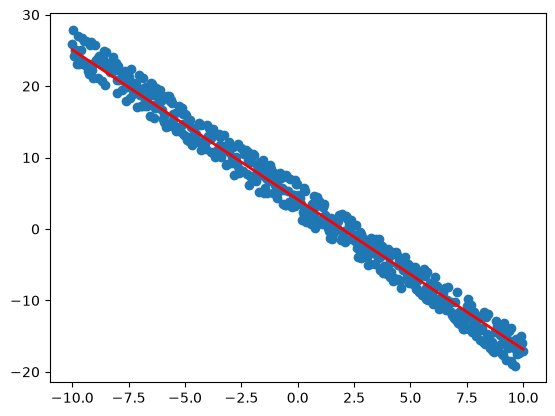

In [145]:
def create_polinomial(power=1,noise=5,upper=10,lower=-10,num_points=500):
    x = np.linspace(lower,upper,num_points)

    y= np.random.rand(1)*2 + np.random.rand(num_points)*noise
    for i in range(power):
        y += x**(i+1) * np.random.randn(1)*2
    return x,y


x,y = create_polinomial()

lr = LinearRegression(1,n_epochs=1000,learning_rate=0.001)
lr.fit(x.reshape(500,1),y)
pred = lr.predict(x.reshape(500,1))
plt.scatter(x,y)
plt.plot(x, pred, color="red", linewidth=2, label=f"pred")


## Logistic Regression

Logistic regression is a model for **binary classification**. As before, we are given $n$ independent observations $\left\{ \left(\mathbf{x}^{(i)}, y^{(i)}\right) \right\}_{i=1}^{n}$ with $\mathbf{x}^{(i)} \in \mathbb{R}^{d}$, but the targets now take values in $\{0, 1\}$. Rather than predicting $y$ directly, the model estimates the probability that an observation belongs to the positive class. It does so by passing the linear score $\mathbf{w}^{\top} \mathbf{x} + b$ through the **sigmoid** (logistic) function

$$
\sigma(z) = \frac{1}{1 + e^{-z}},
$$

which maps any real number to the interval $(0, 1)$. The model is therefore

$$
\hat{p}^{(i)} = P\left(y^{(i)} = 1 \mid \mathbf{x}^{(i)}\right) = \sigma\left(\mathbf{w}^{\top} \mathbf{x}^{(i)} + b\right).
$$


A class label is obtained by thresholding the predicted probability, typically predicting $\hat{y}^{(i)} = 1$ whenever $\hat{p}^{(i)} \geq 0.5$. Since $\sigma(z) \geq 0.5$ exactly when $z \geq 0$, the decision boundary is the hyperplane $\mathbf{w}^{\top} \mathbf{x} + b = 0$. Logistic regression is therefore a linear classifier.

### Training

In linear regression the targets were modeled with Gaussian noise. Here each target is instead modeled as a Bernoulli random variable, $y^{(i)} \mid \mathbf{x}^{(i)} \sim \operatorname{Bernoulli}\left(\hat{p}^{(i)}\right)$. Maximizing the likelihood of the data is then equivalent to minimizing the **binary cross-entropy** (log loss):

$$
\mathcal{L}(\mathbf{w}, b) = -\frac{1}{n} \sum_{i=1}^{n} \left[ y^{(i)} \log \hat{p}^{(i)} + \left(1 - y^{(i)}\right) \log\left(1 - \hat{p}^{(i)}\right) \right].
$$

This loss is convex, so any minimum is a global minimum. Unlike the least-squares problem, however, setting its gradient to zero gives no closed-form solution, so the parameters must be found iteratively. Using the augmented notation and design matrix $\mathbf{X}$ from before, the gradient takes a remarkably simple form:

$$
\nabla \mathcal{L}(\tilde{\mathbf{w}}) = \frac{1}{n} \mathbf{X}^{\top} \left( \sigma(\mathbf{X} \tilde{\mathbf{w}}) - \mathbf{y} \right),
$$

where $\sigma$ is applied element-wise. This expression is structurally identical to the linear regression gradient, with the prediction $\mathbf{X}\tilde{\mathbf{w}}$ replaced by $\sigma(\mathbf{X}\tilde{\mathbf{w}})$. As a result, the same gradient descent and stochastic gradient descent procedures apply with only this change:

$$
\tilde{\mathbf{w}}_{t+1} = \tilde{\mathbf{w}}_{t} - \frac{\eta}{n} \mathbf{X}^{\top} \left( \sigma(\mathbf{X} \tilde{\mathbf{w}}_{t}) - \mathbf{y} \right).
$$

> **Remark.** When the two classes are perfectly linearly separable, the likelihood can be increased indefinitely by scaling up $\tilde{\mathbf{w}}$. The weights then diverge instead of converging. In practice this is prevented by adding a regularization term such as $\lambda \lVert \mathbf{w} \rVert_2^{2}$ to the loss.

In [146]:
def sigmoid(z):
    return 1/(1 + np.exp(-z))

class LogisticRegression:
    def __init__(self, num_features, learning_rate=0.01, n_epochs=100):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.w = np.random.randn(num_features)
        self.b = 0.0

    def fit(self, X, y):
 
        for _ in range(self.n_epochs):
            # Visit the examples in a random order each epoch
            for i in range(X.shape[0]):
                p = sigmoid(X[i] @ self.w + self.b)
                error = p - y[i]
                # Gradient of the cross-entropy for one example is (p - y) * (x_i, 1)
                self.w -= self.learning_rate * error * X[i]
                self.b -= self.learning_rate * error
 
        return self

    def predict_proba(self, X):
            return sigmoid(X @ self.w + self.b)
    
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)
    

Original classes:


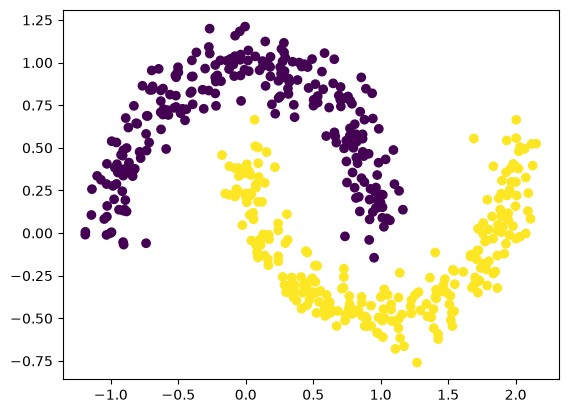

Predicted classes:


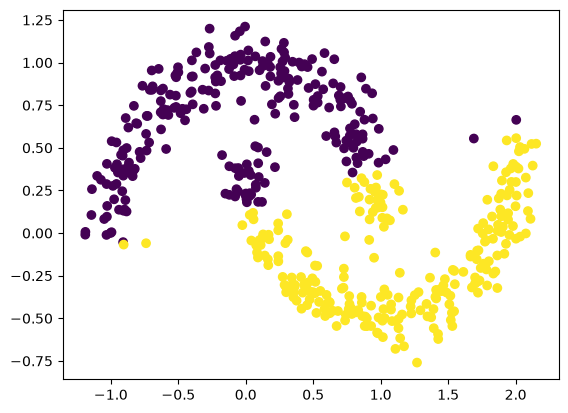

In [147]:
X, y = make_moons(n_samples=500, noise=0.1)
print("Original classes:")
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

log_reg = LogisticRegression(2,n_epochs=1000,learning_rate=0.001)
log_reg.fit(X,y)
preds = log_reg.predict(X)
print("Predicted classes:")
plt.scatter(X[:, 0], X[:, 1], c=preds)
plt.show()


## Underfitting

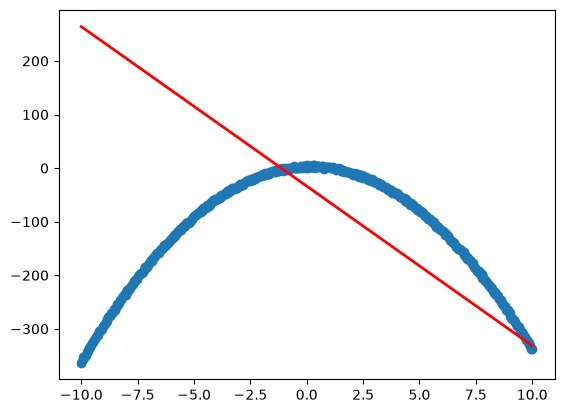

In [158]:
x,y = create_polinomial(power=2,lower=-10,upper=10)
lr = LinearRegression(1,n_epochs=1000,learning_rate=0.001)
lr.fit(x.reshape(500,1),y)
pred = lr.predict(x.reshape(500,1))
plt.scatter(x,y)
plt.plot(x, pred, color="red", linewidth=2, label=f"pred")

## Feature engineering

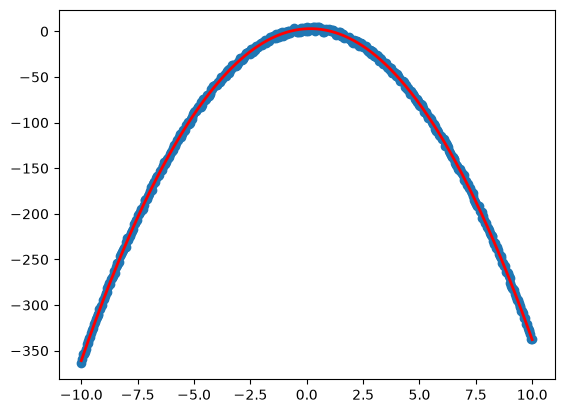

In [159]:
def engineer_features(x,power=2):
    return np.column_stack([ x**(i+1) for i in range(power)])

x_new = engineer_features(x,power=2)

lr = LinearRegression(2,n_epochs=1000,learning_rate=0.00001)
lr.fit(x_new,y)
pred = lr.predict(x_new)
plt.scatter(x,y)
plt.plot(x, pred, color="red", linewidth=2, label=f"pred")

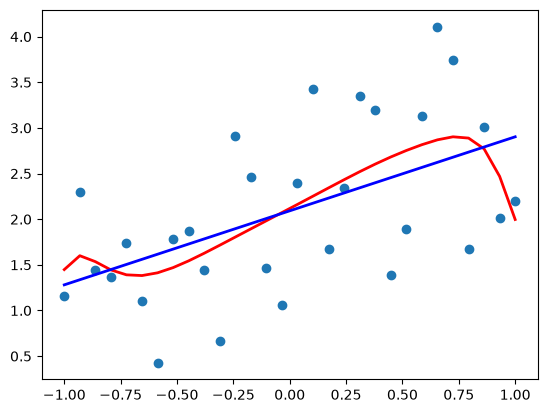

In [164]:
x,y = create_polinomial(power=1,upper=1,lower=-1,num_points=30,noise=3)

x_new = engineer_features(x,power=20)

lr = LinearRegression(20,n_epochs=1000,learning_rate=0.001)
lr.fit(x_new,y)
lr2 = LinearRegression(1,n_epochs=1000,learning_rate=0.001)
lr2.fit(x.reshape(30,1),y)
pred = lr.predict(x_new)
pred2 = lr2.predict(x.reshape(30,1))

plt.scatter(x,y)
plt.plot(x, pred, color="red", linewidth=2, label=f"pred")
plt.plot(x, pred2, color="blue", linewidth=2, label=f"pred")